# Лабораторная работа №1. Метод обратного распространения ошибки

**Цель:** изучить метод обратного распространения ошибки на примере двухслойной полносвязной сети (один скрытый слой) для классификации рукописных цифр MNIST.

**Конфигурация сети:**

- Вход: $28 \times 28 = 784$ нейрона (пиксели изображения), без активации
- Скрытый слой: $s = 300$ нейронов, активация ReLU
- Выход: $k = 10$ нейронов, активация softmax
- Функция ошибки: кросс-энтропия
- Обучение: стохастический градиентный спуск по пачкам (mini-batch SGD)

**Контрольные параметры:** batch size = 32, learning rate = 0.1, 300 скрытых нейронов, 20 эпох.

Реализация — на чистом NumPy, без фреймворков глубокого обучения.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import time
import os
import struct

np.random.seed(42)

## 1. Загрузка данных MNIST

Набор данных: https://www.kaggle.com/datasets/hojjatk/mnist-dataset

Файлы в формате IDX (`train-images.idx3-ubyte` и т.д.). Если файлы Kaggle не найдены, данные скачиваются через `sklearn.datasets.fetch_openml` — это только загрузка, обучение всё равно делается вручную.

Формат IDX очень простой: сначала заголовок (magic number, число объектов, размеры), затем байты данных подряд.

In [12]:
def read_idx(path):
    # Читает файл формата IDX (как в оригинальном MNIST).
    with open(path, 'rb') as f:
        # первые 4 байта: magic number; 3-й байт — тип данных, 4-й — число измерений
        magic = struct.unpack('>I', f.read(4))[0]
        n_dims = magic & 0xFF
        shape = struct.unpack('>' + 'I' * n_dims, f.read(4 * n_dims))
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.reshape(shape)


def find_file(folder, *candidates):
    # Kaggle иногда называет файлы с '.' а иногда с '-': пробуем варианты.
    for name in candidates:
        p = os.path.join(folder, name)
        if os.path.exists(p):
            return p
    return None


def load_mnist(folder='mnist'):
    files = {
        'X_train': ('train-images.idx3-ubyte', 'train-images-idx3-ubyte'),
        'y_train': ('train-labels.idx1-ubyte', 'train-labels-idx1-ubyte'),
        'X_test':  ('t10k-images.idx3-ubyte',  't10k-images-idx3-ubyte'),
        'y_test':  ('t10k-labels.idx1-ubyte',  't10k-labels-idx1-ubyte'),
    }
    paths = {k: find_file(folder, *v) for k, v in files.items()}

    if all(paths.values()):
        print('Загружаю из IDX-файлов в папке', folder)
        return (read_idx(paths['X_train']), read_idx(paths['y_train']),
                read_idx(paths['X_test']),  read_idx(paths['y_test']))

    print('IDX-файлы не найдены, скачиваю через fetch_openml (может занять минуту)')
    from sklearn.datasets import fetch_openml
    mnist = fetch_openml('mnist_784', version=1, as_frame=False)
    X = mnist.data.astype(np.uint8).reshape(-1, 28, 28)
    y = mnist.target.astype(np.int64)
    # в openml-версии первые 60000 — train, последние 10000 — test
    return X[:60000], y[:60000], X[60000:], y[60000:]


X_train_img, y_train, X_test_img, y_test = load_mnist('mnist')

Загружаю из IDX-файлов в папке mnist


### Размерности данных

In [13]:
print('Обучающая выборка:  изображений', X_train_img.shape[0], ', меток', y_train.shape[0])
print('Тестовая выборка:   изображений', X_test_img.shape[0],  ', меток', y_test.shape[0])
print('Форма одного изображения:', X_train_img.shape[1:])
print('Форма одной метки:', y_train[0].shape, '(скаляр), пример:', y_train[0])
print('Тип пикселей:', X_train_img.dtype, ', диапазон:', X_train_img.min(), '..', X_train_img.max())
print('Классы:', np.unique(y_train))

Обучающая выборка:  изображений 60000 , меток 60000
Тестовая выборка:   изображений 10000 , меток 10000
Форма одного изображения: (28, 28)
Форма одной метки: () (скаляр), пример: 5
Тип пикселей: uint8 , диапазон: 0 .. 255
Классы: [0 1 2 3 4 5 6 7 8 9]


### Примеры изображений с метками

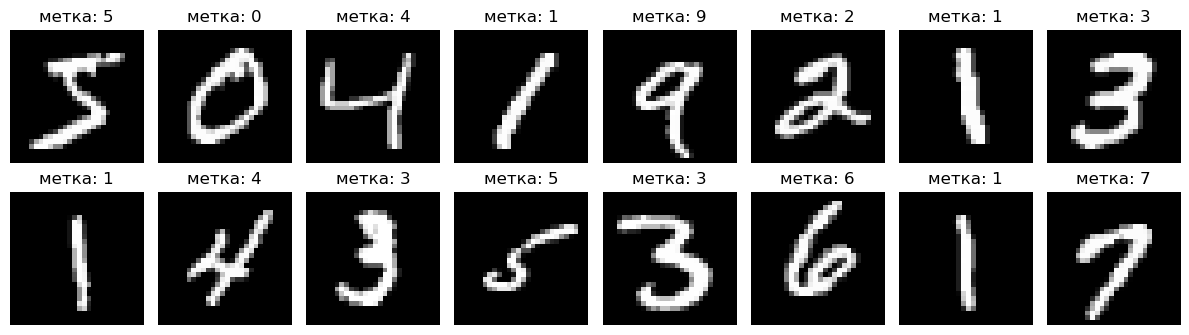

In [14]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_img[i], cmap='gray')
    ax.set_title(f'метка: {y_train[i]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Предобработка

1. **Разворачиваем** каждое изображение $28 \times 28$ в вектор из 784 чисел — полносвязная сеть работает с векторами.
2. **Нормализуем** пиксели в диапазон $[0, 1]$, деля на 255. Без этого значения $z = xW + b$ будут огромными и обучение станет нестабильным.
3. **One-hot кодирование меток**: метку $3$ превращаем в вектор $[0,0,0,1,0,0,0,0,0,0]$. Так метку можно напрямую сравнивать с выходом softmax.

In [15]:
def one_hot(y, num_classes=10):
    Y = np.zeros((y.shape[0], num_classes))
    Y[np.arange(y.shape[0]), y] = 1.0
    return Y


X_train = X_train_img.reshape(-1, 784).astype(np.float64) / 255.0
X_test  = X_test_img.reshape(-1, 784).astype(np.float64) / 255.0
Y_train = one_hot(y_train)
Y_test  = one_hot(y_test)

print('X_train:', X_train.shape, ' Y_train:', Y_train.shape)
print('X_test: ', X_test.shape,  ' Y_test: ', Y_test.shape)
print('Пример one-hot для метки', y_train[0], '->', Y_train[0])

X_train: (60000, 784)  Y_train: (60000, 10)
X_test:  (10000, 784)  Y_test:  (10000, 10)
Пример one-hot для метки 5 -> [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## 3. Математика метода

### Прямой проход

Для пачки из $B$ изображений $X \in \mathbb{R}^{B \times 784}$:

$$Z_1 = X W_1 + b_1, \qquad W_1 \in \mathbb{R}^{784 \times s},\ b_1 \in \mathbb{R}^{s}$$
$$H = \mathrm{ReLU}(Z_1) = \max(0, Z_1)$$
$$Z_2 = H W_2 + b_2, \qquad W_2 \in \mathbb{R}^{s \times 10},\ b_2 \in \mathbb{R}^{10}$$
$$P = \mathrm{softmax}(Z_2), \qquad P_{ik} = \frac{e^{Z_{2,ik}}}{\sum_j e^{Z_{2,ij}}}$$

### Функция ошибки — кросс-энтропия

Для одного примера с one-hot меткой $y$ и предсказанием $p$:

$$L = -\sum_{k} y_k \log p_k = -\log p_{c}, \quad c \text{ — правильный класс}$$

По пачке усредняем: $\mathcal{L} = \frac{1}{B}\sum_i L_i$.

### Обратный проход

**Градиент по логитам.** Ключевой факт: производная кросс-энтропии от softmax по логитам очень простая. Для одного примера:

$$\frac{\partial L}{\partial z_k} = p_k - y_k$$

*Вывод.* $L = -\sum_j y_j \log p_j$, где $p_j = e^{z_j} / \sum_m e^{z_m}$. Тогда $\log p_j = z_j - \log\sum_m e^{z_m}$, и

$$\frac{\partial \log p_j}{\partial z_k} = \delta_{jk} - p_k$$

Подставляя: $\frac{\partial L}{\partial z_k} = -\sum_j y_j (\delta_{jk} - p_k) = -y_k + p_k \sum_j y_j = p_k - y_k$, так как $\sum_j y_j = 1$.

В матричной форме для пачки (с учётом усреднения по $B$):

$$dZ_2 = \frac{1}{B}(P - Y)$$

**Линейный слой.** Для любого слоя $Z = A W + b$, зная $dZ = \partial\mathcal{L}/\partial Z$:

$$dW = A^T dZ, \qquad db = \sum_{i} dZ_i \ (\text{сумма по строкам}), \qquad dA = dZ\, W^T$$

**ReLU.** Производная равна 1 там, где $Z_1 > 0$, и 0 иначе:

$$dZ_1 = dH \odot \mathbb{1}[Z_1 > 0]$$

Итого, последовательность обратного прохода:

$$dZ_2 = \tfrac{1}{B}(P - Y)$$
$$dW_2 = H^T dZ_2, \quad db_2 = \textstyle\sum_i dZ_{2,i}$$
$$dH = dZ_2 W_2^T$$
$$dZ_1 = dH \odot \mathbb{1}[Z_1 > 0]$$
$$dW_1 = X^T dZ_1, \quad db_1 = \textstyle\sum_i dZ_{1,i}$$

### Обновление весов (SGD)

$$W \leftarrow W - \eta\, dW, \qquad b \leftarrow b - \eta\, db$$

где $\eta$ — скорость обучения.

### Инициализация весов

Нулевая инициализация ломает обучение: все нейроны скрытого слоя получают одинаковые градиенты и остаются копиями друг друга. Слишком маленькие случайные веса приводят к затуханию сигнала и медленному обучению (~95% точности).

Используем **инициализацию He** (для ReLU): $W \sim \mathcal{N}(0, \sqrt{2 / n_{in}})$. Дисперсия $2/n_{in}$ подобрана так, чтобы дисперсия $z = \sum_i x_i w_i$ не росла и не затухала от слоя к слою (двойка компенсирует то, что ReLU обнуляет половину значений). Смещения инициализируем нулями.

## 4. Реализация

In [16]:
def relu(z):
    return np.maximum(0.0, z)


def softmax(z):
    # Вычитаем максимум по строке для численной устойчивости:
    # exp(z - max) / sum(exp(z - max)) математически равно softmax(z),
    # но не переполняется при больших z.
    z_shift = z - z.max(axis=1, keepdims=True)
    e = np.exp(z_shift)
    return e / e.sum(axis=1, keepdims=True)


def cross_entropy(P, Y, eps=1e-12):
    # Средняя кросс-энтропия по пачке. eps защищает log от нуля.
    return -np.mean(np.sum(Y * np.log(P + eps), axis=1))

In [17]:
class TwoLayerNet:
    def __init__(self, n_in=784, n_hidden=300, n_out=10):
        # Инициализация He для слоёв с ReLU
        self.W1 = np.random.randn(n_in, n_hidden) * np.sqrt(2.0 / n_in)
        self.b1 = np.zeros(n_hidden)
        self.W2 = np.random.randn(n_hidden, n_out) * np.sqrt(2.0 / n_hidden)
        self.b2 = np.zeros(n_out)

    def forward(self, X):
        # Сохраняем промежуточные значения — они понадобятся в backward.
        self.X  = X
        self.Z1 = X @ self.W1 + self.b1       # (B, s)
        self.H  = relu(self.Z1)               # (B, s)
        self.Z2 = self.H @ self.W2 + self.b2  # (B, 10)
        self.P  = softmax(self.Z2)            # (B, 10)
        return self.P

    def backward(self, Y):
        B = Y.shape[0]

        # Градиент по логитам: (P - Y) / B — усреднение по пачке "спрятано" сюда
        dZ2 = (self.P - Y) / B                 # (B, 10)

        # Выходной слой
        dW2 = self.H.T @ dZ2                   # (s, 10)
        db2 = dZ2.sum(axis=0)                  # (10,)

        # Прокидываем градиент в скрытый слой
        dH  = dZ2 @ self.W2.T                  # (B, s)

        # Через ReLU: пропускаем только там, где Z1 > 0
        dZ1 = dH * (self.Z1 > 0)               # (B, s)

        # Скрытый слой
        dW1 = self.X.T @ dZ1                   # (784, s)
        db1 = dZ1.sum(axis=0)                  # (s,)

        return dW1, db1, dW2, db2

    def update(self, grads, lr):
        dW1, db1, dW2, db2 = grads
        self.W1 -= lr * dW1
        self.b1 -= lr * db1
        self.W2 -= lr * dW2
        self.b2 -= lr * db2

    def predict(self, X, batch_size=1000):
        # Предсказание по частям, чтобы не держать в памяти огромные матрицы
        preds = []
        for i in range(0, X.shape[0], batch_size):
            P = self.forward(X[i:i + batch_size])
            preds.append(P.argmax(axis=1))
        return np.concatenate(preds)

    def error_rate(self, X, y):
        # Доля неправильно классифицированных примеров
        return np.mean(self.predict(X) != y)

### Проверка градиентов численно

Прежде чем обучать, убедимся, что аналитические градиенты из `backward` совпадают с численными (конечные разности). Это стандартный способ поймать ошибку в формулах. Используем маленькую сеть и маленькую пачку, иначе будет долго.

In [18]:
def numerical_gradient(net, X, Y, param, n_checks=10, h=1e-5):
    # Для нескольких случайных элементов параметра считаем (L(w+h) - L(w-h)) / 2h
    rng = np.random.RandomState(0)
    results = []
    for _ in range(n_checks):
        idx = tuple(rng.randint(0, d) for d in param.shape)
        old = param[idx]
        param[idx] = old + h
        L_plus = cross_entropy(net.forward(X), Y)
        param[idx] = old - h
        L_minus = cross_entropy(net.forward(X), Y)
        param[idx] = old
        results.append((idx, (L_plus - L_minus) / (2 * h)))
    return results


small_net = TwoLayerNet(n_in=784, n_hidden=20, n_out=10)
Xs, Ys = X_train[:5], Y_train[:5]
small_net.forward(Xs)
dW1, db1, dW2, db2 = small_net.backward(Ys)

for name, param, grad in [('W1', small_net.W1, dW1), ('b1', small_net.b1, db1),
                          ('W2', small_net.W2, dW2), ('b2', small_net.b2, db2)]:
    max_err = 0.0
    for idx, num in numerical_gradient(small_net, Xs, Ys, param):
        ana = grad[idx]
        max_err = max(max_err, abs(num - ana) / (abs(num) + abs(ana) + 1e-12))
    print(f'{name}: максимальная относительная ошибка = {max_err:.2e}')

W1: максимальная относительная ошибка = 3.01e-09
b1: максимальная относительная ошибка = 4.92e-10
W2: максимальная относительная ошибка = 5.48e-09
b2: максимальная относительная ошибка = 9.42e-11


Относительные ошибки порядка $10^{-7}$ и меньше означают, что формулы обратного прохода верны.

## 5. Обучение

In [19]:
def train(net, X, Y, y, X_test, y_test, epochs=20, batch_size=32, lr=0.1, verbose=True):
    n = X.shape[0]
    history = {'train_loss': [], 'train_err': [], 'test_err': [], 'epoch_time': []}

    for epoch in range(1, epochs + 1):
        t0 = time.time()

        # Перемешиваем данные, чтобы пачки каждый раз были разными
        perm = np.random.permutation(n)
        X_sh, Y_sh = X[perm], Y[perm]

        loss_sum = 0.0
        for i in range(0, n, batch_size):
            Xb = X_sh[i:i + batch_size]
            Yb = Y_sh[i:i + batch_size]

            P = net.forward(Xb)
            loss_sum += cross_entropy(P, Yb) * Xb.shape[0]
            grads = net.backward(Yb)
            net.update(grads, lr)

        epoch_time = time.time() - t0
        train_loss = loss_sum / n
        train_err = net.error_rate(X, y)
        test_err = net.error_rate(X_test, y_test)

        history['train_loss'].append(train_loss)
        history['train_err'].append(train_err)
        history['test_err'].append(test_err)
        history['epoch_time'].append(epoch_time)

        if verbose:
            print(f'Эпоха {epoch:2d}/{epochs} | loss = {train_loss:.4f} | '
                  f'ошибка train = {train_err * 100:5.2f}% | '
                  f'ошибка test = {test_err * 100:5.2f}% | '
                  f'время {epoch_time:.1f} с')
    return history

In [20]:
BATCH_SIZE = 32
LEARNING_RATE = 0.1
HIDDEN = 300
EPOCHS = 20

np.random.seed(42)
net = TwoLayerNet(n_in=784, n_hidden=HIDDEN, n_out=10)

t_start = time.time()
history = train(net, X_train, Y_train, y_train, X_test, y_test,
                epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LEARNING_RATE)
print(f'\nОбщее время обучения: {time.time() - t_start:.1f} с')

Эпоха  1/20 | loss = 0.2870 | ошибка train =  4.54% | ошибка test =  4.56% | время 13.0 с
Эпоха  2/20 | loss = 0.1324 | ошибка train =  2.80% | ошибка test =  3.23% | время 11.8 с
Эпоха  3/20 | loss = 0.0941 | ошибка train =  2.04% | ошибка test =  2.87% | время 12.0 с
Эпоха  4/20 | loss = 0.0719 | ошибка train =  1.43% | ошибка test =  2.36% | время 11.5 с
Эпоха  5/20 | loss = 0.0577 | ошибка train =  1.41% | ошибка test =  2.60% | время 11.7 с
Эпоха  6/20 | loss = 0.0476 | ошибка train =  0.97% | ошибка test =  2.15% | время 11.5 с
Эпоха  7/20 | loss = 0.0399 | ошибка train =  0.78% | ошибка test =  2.16% | время 11.4 с
Эпоха  8/20 | loss = 0.0330 | ошибка train =  0.57% | ошибка test =  2.06% | время 11.2 с
Эпоха  9/20 | loss = 0.0279 | ошибка train =  0.46% | ошибка test =  2.01% | время 11.4 с
Эпоха 10/20 | loss = 0.0235 | ошибка train =  0.37% | ошибка test =  1.97% | время 11.4 с
Эпоха 11/20 | loss = 0.0194 | ошибка train =  0.28% | ошибка test =  2.01% | время 11.5 с
Эпоха 12/2

## 6. Результаты на тестовой выборке

In [21]:
test_err = net.error_rate(X_test, y_test)
print(f'Ошибка классификации на тестовой выборке: {test_err * 100:.2f}%')
print(f'Точность на тестовой выборке:             {(1 - test_err) * 100:.2f}%')

Ошибка классификации на тестовой выборке: 1.82%
Точность на тестовой выборке:             98.18%


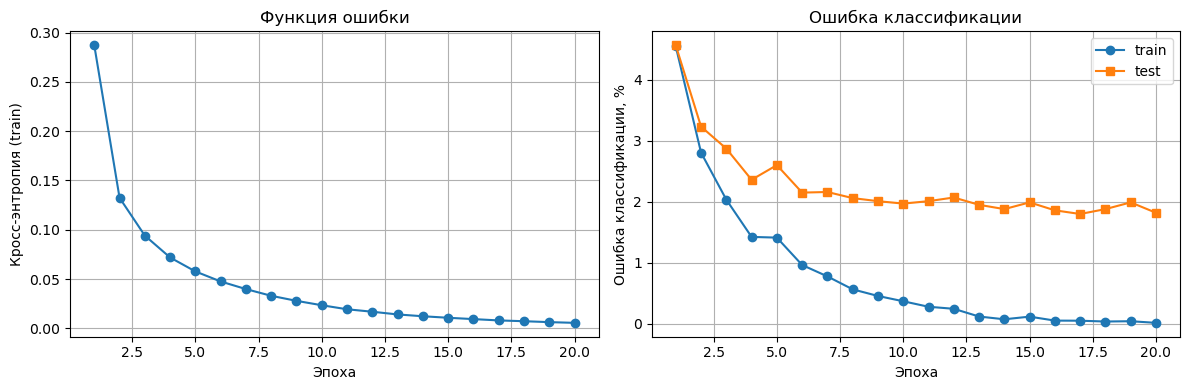

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, EPOCHS + 1), history['train_loss'], marker='o')
axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Кросс-энтропия (train)')
axes[0].set_title('Функция ошибки'); axes[0].grid(True)

axes[1].plot(range(1, EPOCHS + 1), np.array(history['train_err']) * 100, marker='o', label='train')
axes[1].plot(range(1, EPOCHS + 1), np.array(history['test_err']) * 100, marker='s', label='test')
axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Ошибка классификации, %')
axes[1].set_title('Ошибка классификации'); axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.show()

### Примеры ошибок сети

Всего ошибок на тесте: 182


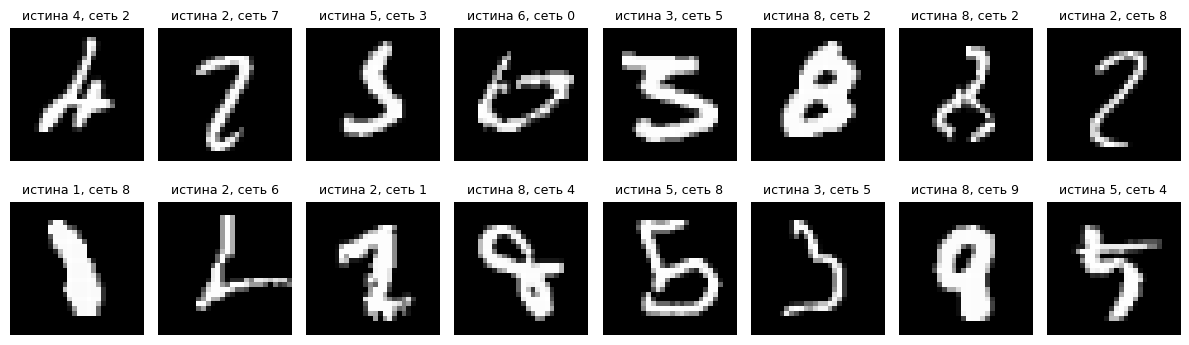

In [23]:
pred_test = net.predict(X_test)
wrong = np.where(pred_test != y_test)[0]
print('Всего ошибок на тесте:', len(wrong))

fig, axes = plt.subplots(2, 8, figsize=(12, 3.8))
for ax, i in zip(axes.flat, wrong[:16]):
    ax.imshow(X_test_img[i], cmap='gray')
    ax.set_title(f'истина {y_test[i]}, сеть {pred_test[i]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Матрица ошибок

Строка — истинный класс, столбец — предсказанный. Видно, какие цифры сеть путает чаще всего.

In [24]:
conf = np.zeros((10, 10), dtype=int)
for t, p in zip(y_test, pred_test):
    conf[t, p] += 1

print('      ' + ' '.join(f'{k:5d}' for k in range(10)))
for t in range(10):
    print(f'{t:3d}:  ' + ' '.join(f'{conf[t, p]:5d}' for p in range(10)))

          0     1     2     3     4     5     6     7     8     9
  0:    969     1     1     1     1     1     3     1     1     1
  1:      0  1127     2     1     0     1     2     1     1     0
  2:      4     3  1004     3     4     0     2     4     8     0
  3:      0     0     3   990     0     4     0     2     3     8
  4:      2     0     2     0   967     0     3     1     0     7
  5:      2     0     0     6     1   873     4     0     3     3
  6:      3     4     0     1     3     4   942     0     1     0
  7:      0     4     3     1     0     0     0  1012     5     3
  8:      3     1     2     3     5     2     3     2   951     2
  9:      1     3     0     5     7     1     1     4     4   983


## 7. Что на самом деле выучил скрытый слой

Каждый столбец $W_1$ — это 784 веса, по одному на пиксель. Их можно нарисовать как картинку $28 \times 28$: получается "шаблон", на который реагирует нейрон.

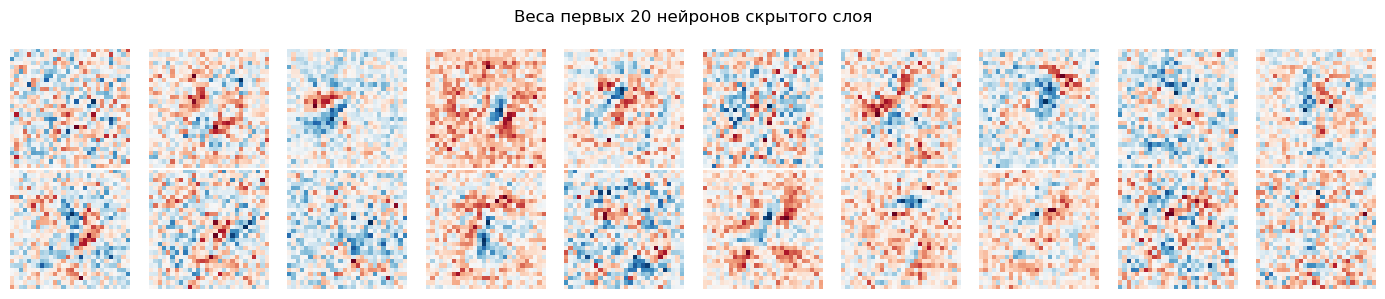

In [25]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for j, ax in enumerate(axes.flat):
    ax.imshow(net.W1[:, j].reshape(28, 28), cmap='RdBu')
    ax.axis('off')
plt.suptitle('Веса первых 20 нейронов скрытого слоя')
plt.tight_layout()
plt.show()

## 8. Выводы

- Реализован метод обратного распространения ошибки для двухслойной полносвязной сети на чистом NumPy.
- Выведены формулы градиентов: ключевое упрощение — производная кросс-энтропии от softmax по логитам равна $P - Y$.
- Корректность формул подтверждена численной проверкой градиентов.
- На контрольных параметрах (batch size 32, lr 0.1, 300 скрытых нейронов, 20 эпох) достигнута точность на тестовой выборке около 98%, что сравнимо с результатами стандартных фреймворков для такой архитектуры.
- Инициализация He оказалась критична: с малыми случайными весами сеть обучается заметно медленнее.